# EDA, Cleaning and Preprocessing

**Goal:** understand the Hotel Booking Demand data, clean it, engineer features, and build the shared train/test split and preprocessing pipeline that all three modules use (Price Advisor, Cancellation Risk, Guest Insights).



| Section | What happens |
|---|---|
| 0 | Setup and configuration |
| 1 | Load and inspect the raw data |
| 2 | Data-quality audit: what is wrong and what we decide to do |
| 3 | Exploratory data analysis (on the raw data) and written insights |
| 4 | Cleaning: leakage, missing values, impossible rows, duplicates |
| 5 | Feature engineering |
| 6 | Train/test split and preprocessing pipeline |
| 7 | Save and summary |



## 0. Setup

In [1]:
import pandas as pd 
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# ---- Configuration ----
DATA_RAW = Path("../data/hotel_bookings.csv")
DATA_CLEAN = Path("../data/clean/hotel_clean.csv")
RANDOM_STATE = 42
TEST_SIZE = 0.2
ADR_MAX = 1000                      # upper ADR cut-off, justified in section 4.3

LEAKAGE_COLS = ["reservation_status", "reservation_status_date"]
TARGETS = ["is_canceled", "adr"]
ID_LIKE_COLS = ["agent", "company"]  # numeric codes, not quantities

MONTH_ORDER = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]

SEASON_MAP = {
    "December": "winter", "January": "winter", "February": "winter",
    "March": "spring", "April": "spring", "May": "spring",
    "June": "summer", "July": "summer", "August": "summer",
    "September": "autumn", "October": "autumn", "November": "autumn",
}

pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")


In [2]:
def cancel_rate(data, col, order=None, plot=True):
    """Show the cancellation rate and group size (n) for each category of `col`."""
    g = data.groupby(col, observed=True)["is_canceled"].agg(rate="mean", n="size")
    if order is not None:
        g = g.reindex(order)
    if plot:
        ax = g["rate"].plot(kind="bar", figsize=(8, 4))
        ax.set_ylabel("cancellation rate")
        ax.set_title(f"Cancellation rate by {col}")
        plt.show()
    display(g.round(3))


cleaning_log = []


def log_step(name, data):
    """Record the number of rows after a cleaning step."""
    previous = cleaning_log[-1]["rows"] if cleaning_log else len(data)
    removed = previous - len(data)
    cleaning_log.append({"step": name, "rows": len(data), "removed": removed})
    print(f"{name}: {len(data):,} rows ({removed:,} removed)")

## 1. Load and inspect

`raw` is the original data and is never modified. Every later step works on a copy.

In [3]:
raw = pd.read_csv(DATA_RAW)
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")   # .shape is an attribute, not a method
raw.head()

119,390 rows x 32 columns


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [4]:

# Use .info() to get a quick, concise structural health check of the dataframe 
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [5]:
# Use .describe() to get a comprehensive statistical summary of the datasets's distribution 
raw.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [6]:
# Numeric columns: look at min / max / quartiles for impossible values and outliers
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.37,0.48,0.00,0.00,0.00,1.0,1.0
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0


In [7]:
# Text columns: number of unique values, most common value and its frequency
raw.select_dtypes(exclude="number").describe().T

,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


In [8]:
# Missing values
raw.isna().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

## 2. Data-quality audit

In [9]:
print(raw.duplicated().sum())

31994


In [10]:
print( raw["deposit_type"].value_counts())
print("\n",raw["is_canceled"].value_counts(normalize=True))
print("\n",raw["country"].value_counts().head(10))
print("\n",raw["agent"].value_counts(dropna=False))
print("\n",raw["hotel"].value_counts(normalize=True)* 100)


deposit_type
No Deposit    104641
Non Refund     14587
Refundable       162
Name: count, dtype: int64

 is_canceled
0    0.629584
1    0.370416
Name: proportion, dtype: float64

 country
PRT    48590
GBR    12129
FRA    10415
ESP     8568
DEU     7287
ITA     3766
IRL     3375
BEL     2342
BRA     2224
NLD     2104
Name: count, dtype: int64

 agent
9.0      31961
NaN      16340
240.0    13922
1.0       7191
14.0      3640
         ...  
444.0        1
408.0        1
388.0        1
453.0        1
480.0        1
Name: count, Length: 334, dtype: int64

 hotel
City Hotel      66.446101
Resort Hotel    33.553899
Name: proportion, dtype: float64


In [11]:
raw["meal"].value_counts(normalize=True) * 100

meal
BB           77.318033
HB           12.114080
SC            8.920345
Undefined     0.979144
FB            0.668398
Name: proportion, dtype: float64

In [12]:
raw.groupby("deposit_type")["is_canceled"].mean()

deposit_type
No Deposit    0.283770
Non Refund    0.993624
Refundable    0.222222
Name: is_canceled, dtype: float64

In [13]:
raw[raw["deposit_type"] == "Non Refund"]["market_segment"].value_counts()


market_segment
Groups           9172
Offline TA/TO    5006
Corporate         334
Online TA          56
Direct             19
Name: count, dtype: int64

In [14]:
# Do Groups cancel more even WITHOUT a non-refund deposit?
raw[raw["deposit_type"] == "No Deposit"].groupby("market_segment")["is_canceled"].mean()



market_segment
Aviation         0.219409
Complementary    0.130552
Corporate        0.136978
Direct           0.152293
Groups           0.282996
Offline TA/TO    0.172107
Online TA        0.366434
Undefined        1.000000
Name: is_canceled, dtype: float64

In [15]:
# Does PRT cancel more WITHOUT a non-refund deposit?
raw[raw["deposit_type"] == "No Deposit"].groupby(raw["country"] == "PRT")["is_canceled"].mean()

country
False    0.232487
True     0.388640
Name: is_canceled, dtype: float64

### Findings and decisions

| # | Finding | Evidence | Decision (section) |
|---|---|---|---|
| 1 | **Leakage** | `reservation_status` and `reservation_status_date` record the outcome | Drop  |
| 2 | **Missing values** | `children` 4, `country` 488, `agent` 16,340, `company` 112,593 (94%) | Drop `company`; `children` to 0; `country` and `agent` to "Unknown" |
| 3 | **Duplicate label** | `meal` has both "Undefined" and "SC"; both mean no meal package | Merge into "SC"  |
| 4 | **Impossible values** | negative ADR, ADR of 5,400 (next highest is 510), 0 guests, 0 nights | Remove those rows  |
| 5 | **Duplicate rows** | about 32,000 exact copies (no booking ID, so some could be genuine) | Drop, then measure the effect  |
| 6 | **Suspicious label** | `deposit_type = Non Refund` cancels 99% of the time | Keep, but test the model with and without it |
| 7 | **ADR = 0 rows** | complimentary or house-use stays are probably in here | Keep for now; revisit for Module A |


## 3. Exploratory data analysis
`eda` is a copy of `raw` with one extra column, `lead_bucket`, so the helper column never reaches the cleaned data.

In [16]:
eda = raw.copy()
eda["lead_bucket"] = pd.cut(
    eda["lead_time"],
    bins=[-1, 7, 30, 90, 180, 365, np.inf],
    labels=["0-7", "8-30", "31-90", "91-180", "181-365", "365+"],
)

### 3.1 Cancellation rate by month, hotel, deposit type and market segment

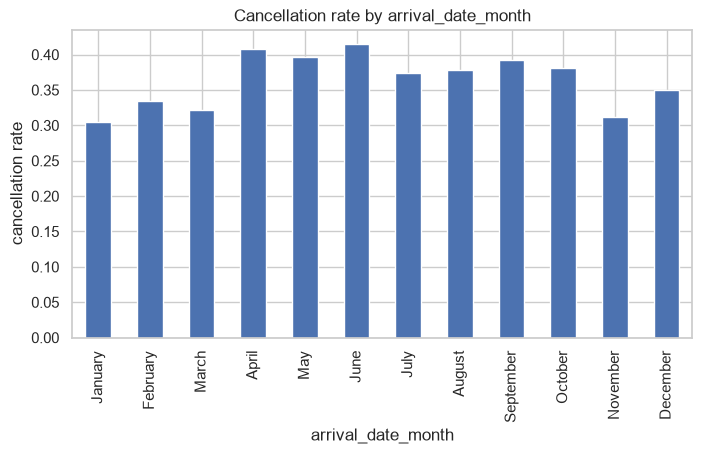

,rate,n
arrival_date_month,,
January,0.305,5929
February,0.334,8068
March,0.322,9794
April,0.408,11089
May,0.397,11791
June,0.415,10939
July,0.375,12661
August,0.378,13877
September,0.392,10508


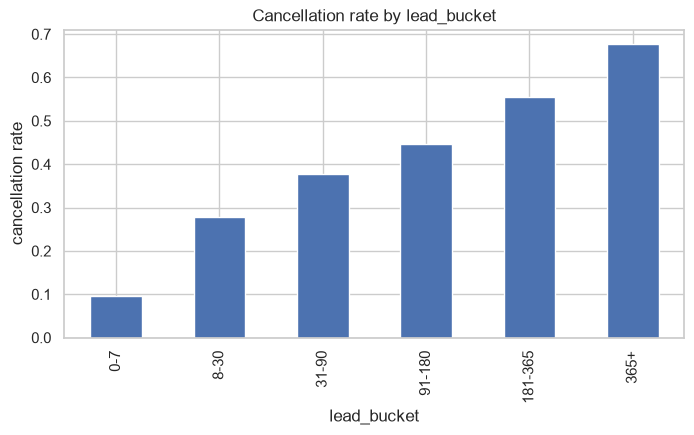

,rate,n
lead_bucket,,
0-7,0.096,19746
8-30,0.279,18960
31-90,0.377,29553
91-180,0.447,26439
181-365,0.555,21544
365+,0.677,3148


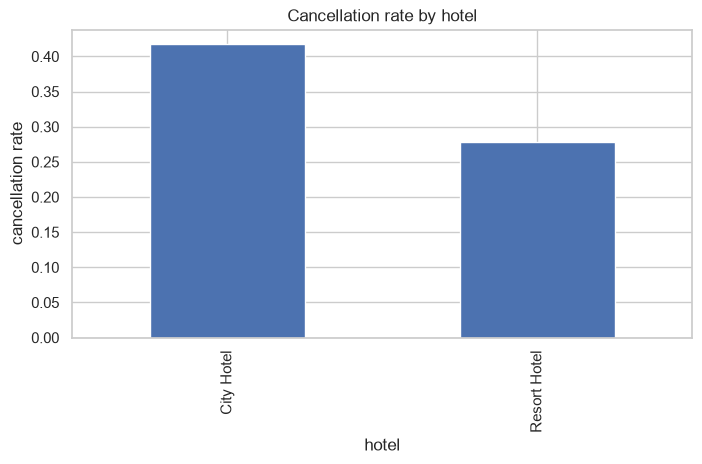

,rate,n
hotel,,
City Hotel,0.417,79330
Resort Hotel,0.278,40060


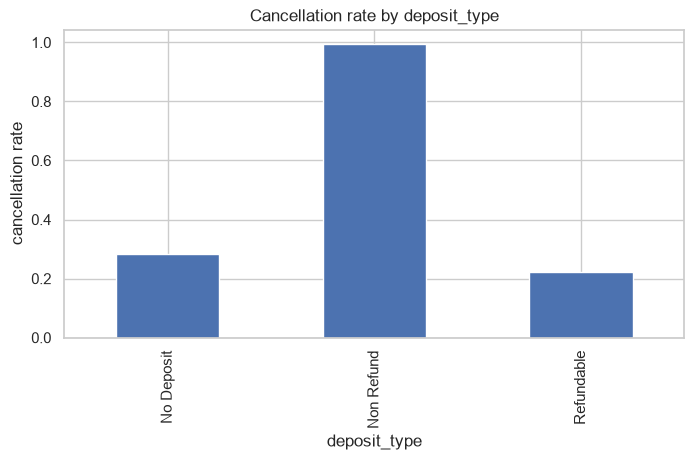

,rate,n
deposit_type,,
No Deposit,0.284,104641
Non Refund,0.994,14587
Refundable,0.222,162


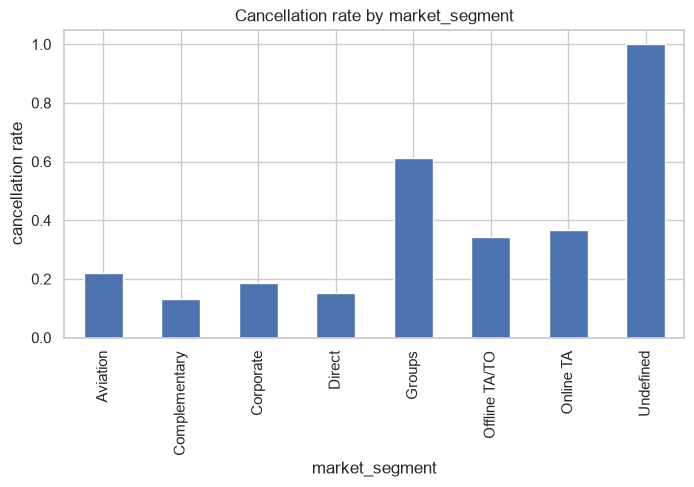

,rate,n
market_segment,,
Aviation,0.219,237
Complementary,0.131,743
Corporate,0.187,5295
Direct,0.153,12606
Groups,0.611,19811
Offline TA/TO,0.343,24219
Online TA,0.367,56477
Undefined,1.000,2


In [17]:

cancel_rate(raw, "arrival_date_month", order=MONTH_ORDER)
cancel_rate(eda, "lead_bucket")
cancel_rate(eda, "hotel")
cancel_rate(eda, "deposit_type")
cancel_rate(eda, "market_segment")


### 3.2 Cancellation rate by lead time

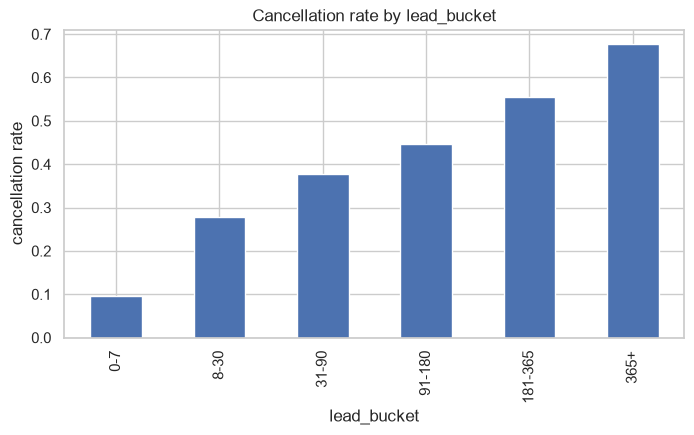

,rate,n
lead_bucket,,
0-7,0.096,19746
8-30,0.279,18960
31-90,0.377,29553
91-180,0.447,26439
181-365,0.555,21544
365+,0.677,3148


In [18]:
cancel_rate(eda, "lead_bucket")

In [19]:
eda[eda["deposit_type"]=="No Deposit"].groupby("lead_bucket")["is_canceled"].mean()

lead_bucket
0-7        0.091646
8-30       0.260440
31-90      0.321898
91-180     0.348607
181-365    0.398240
365+       0.206250
Name: is_canceled, dtype: float64

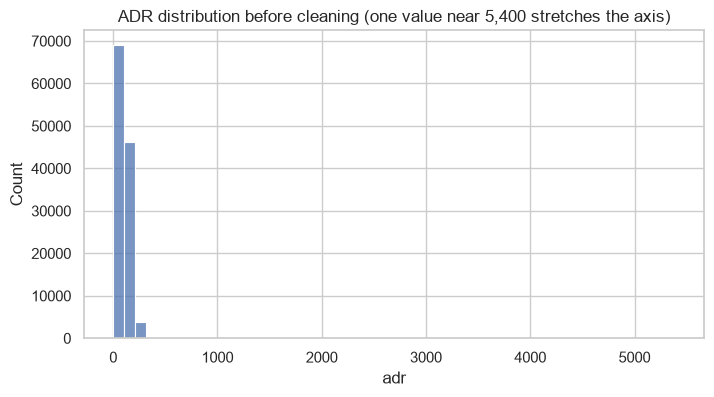

In [20]:
# ADR distribution, and ADR by month and hotel

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(raw["adr"], bins=50, ax=ax)
ax.set_title("ADR distribution before cleaning (one value near 5,400 stretches the axis)")
plt.show()

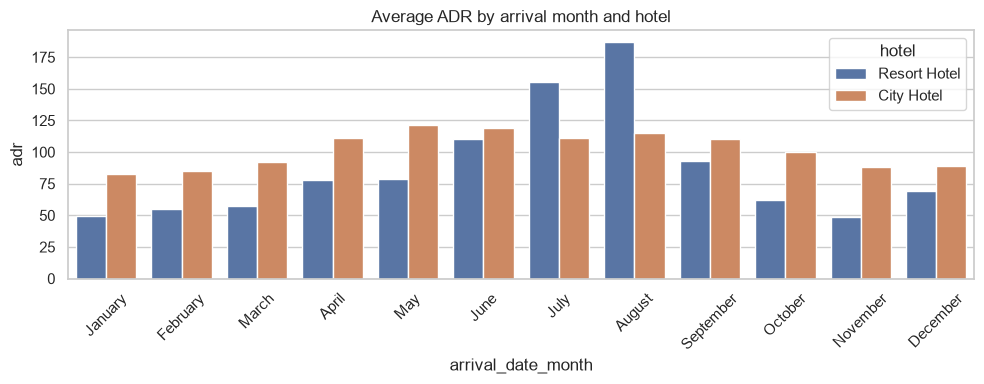

In [21]:
# Use only plausible ADR values so a single outlier cannot distort the averages
adr_plot = eda[eda["adr"].between(0, ADR_MAX)]

plt.figure(figsize=(10, 4))
sns.barplot(data=adr_plot, x="arrival_date_month", y="adr", hue="hotel",
            order=MONTH_ORDER, errorbar=None)
plt.xticks(rotation=45)
plt.title("Average ADR by arrival month and hotel")
plt.tight_layout()
plt.show()

### 3.4 Correlation with the target

`agent` and `company` are ID codes, so a correlation with them means nothing and they are left out. The heatmap covers numeric columns only, so it cannot show categorical features such as `deposit_type`.

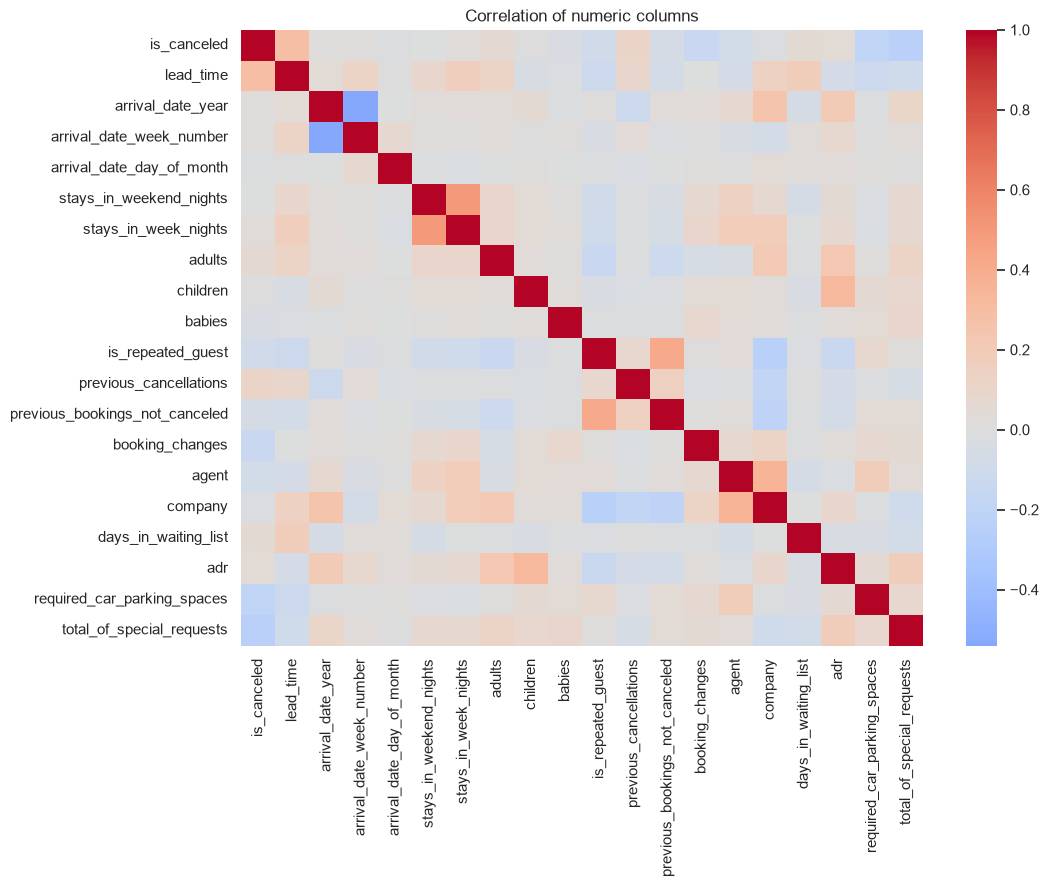

is_canceled                       1.000000
lead_time                         0.293123
total_of_special_requests         0.234658
required_car_parking_spaces       0.195498
booking_changes                   0.144381
previous_cancellations            0.110133
is_repeated_guest                 0.084793
agent                             0.083114
adults                            0.060017
previous_bookings_not_canceled    0.057358
days_in_waiting_list              0.054186
adr                               0.047557
babies                            0.032491
stays_in_week_nights              0.024765
company                           0.020642
arrival_date_year                 0.016660
arrival_date_week_number          0.008148
arrival_date_day_of_month         0.006130
children                          0.005048
stays_in_weekend_nights           0.001791
Name: is_canceled, dtype: float64

In [22]:
# Correlation with the target

corr = raw.select_dtypes("number").corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation of numeric columns")
plt.show()

corr["is_canceled"].abs().sort_values(ascending=False)

In [23]:
# Class balance
balance = raw["is_canceled"].value_counts(normalize=True).rename({0: "not cancelled", 1: "cancelled"})
display(balance.round(3).to_frame("share"))
print(f"A model that always predicts 'not cancelled' scores {balance['not cancelled']:.1%} accuracy on the raw data.")

,share
is_canceled,
not cancelled,0.63
cancelled,0.37


A model that always predicts 'not cancelled' scores 63.0% accuracy on the raw data.


### Written insights

Numbers below come from the raw data.

1. **Deposit type looks like the strongest signal, but it is suspicious.** Non Refund bookings cancel 99.4% of the time (n = 14,587), against 28.4% for No Deposit and 22.2% for Refundable (n = 162, too small to trust). A real non-refundable deposit should *reduce* cancellations, so this label probably reflects how the data was recorded rather than guest behaviour. About 63% of Non Refund bookings are Groups, which is why Groups look high overall (61.1%) yet cancel at 28.3% inside No Deposit, the same as average. Country matters on its own: Portuguese guests cancel at 38.9% against 23.2% for others inside No Deposit.
2. **Lead time matters, but part of the pattern comes from Non Refund.** Overall, cancellation rises from 9.6% (0-7 days) to 67.7% (365+ days). With Non Refund removed it still rises from 9.2% to 39.8% (181-365 days), then falls to 20.6% for 365+. So the jump in the longest bucket appears to come from Non Refund bookings, and the group sizes (n) in the table should be checked before trusting that bucket.
3. **Hotel and season.** The City Hotel cancels 41.7% of bookings against 27.8% for the Resort. Cancellation stays between 30% (January) and 41% (June) across months. Price is far more seasonal: Resort ADR is roughly 50 in winter, about 155 in July and 187 in August, while City ADR is flatter (roughly 82 to 122).
4. **No single numeric feature explains cancellation.** `lead_time` has the highest correlation (0.29), followed by `total_of_special_requests` (0.23), `required_car_parking_spaces` (0.20), `booking_changes` (0.14) and `previous_cancellations` (0.11). Everything is below 0.3, and correlation only sees linear patterns, so models that combine features and capture non-linear effects are worth testing.
5. **ADR is right-skewed with one extreme error, and the class balance shifts after cleaning.** One booking at 5,400 (the next highest is 510) stretches the ADR axis. The raw cancellation rate is 37.0%, but after cleaning (mainly removing about 32,000 duplicate rows) it drops to 27.5%, so the majority-class baseline is 72.5% accuracy, not 63%.

## 4. Cleaning

All steps work on `df`, a copy of `raw`. After each step the row count is logged.

In [24]:
df = raw.copy()
log_step("start", df)

start: 119,390 rows (0 removed)


### 4.1 Drop the leakage columns

The reservation_status and the reservation_date_change is not exist at the prediction time and it will reveal the outcome. So we will drop them 

In [25]:
df = df.drop(columns=LEAKAGE_COLS)


### 4.2 Missing values and labels

| Column | Fix | Reason |
|---|---|---|
| `company` | drop | 94% missing, nothing to learn from |
| `children` | fill with 0 | only 4 missing, 0 is the sensible default |
| `country` | fill with "Unknown" | a missing country is a category of its own |
| `agent` | fill with "Unknown", convert IDs to text | missing means no agent (a direct booking); agent IDs have no order, so they are categories |
| `meal` | "Undefined" becomes "SC" | both mean no meal package |

These fills are fixed values, not statistics learned from the data, so they cannot leak and are safe before the split.

In [26]:
df = df.drop(columns=["company"])
df["children"] = df["children"].fillna(0).astype(int)
df["country"] = df["country"].fillna("Unknown")

# .apply runs the lambda on every value: missing -> "Unknown", otherwise 9.0 -> "9"
df["agent"] = df["agent"].apply(lambda x: "Unknown" if pd.isna(x) else str(int(x)))

df["meal"] = df["meal"].replace("Undefined", "SC")

assert df.isna().sum().sum() == 0, "missing values remain"
log_step("after missing-value fixes", df)

after missing-value fixes: 119,390 rows (0 removed)


### 4.3 Remove impossible rows

Flag each problem separately first, so we can see how many rows each one affects and how much they overlap.

**Choosing the ADR cut-off.** The top ADR values below are 510, 508, 451.5 and so on, falling gradually. 5,400 is the only break in the pattern, so a cut-off of 1,000 sits inside that gap and removes the error without touching real expensive bookings.

In [27]:
# Checking the values 
bad_adr_neg = df["adr"] < 0
no_guests = (df["adults"] + df["children"] + df["babies"] ) == 0
no_nights = (df["stays_in_week_nights"] + df["stays_in_weekend_nights"]) == 0 

print(bad_adr_neg.sum(), no_guests.sum(), no_nights.sum())

1 180 715


In [28]:
# checking the adr column 
print(df["adr"].quantile([0.99, 0.999, 0.9999]))
print(df["adr"].sort_values(ascending=False).head(10))

0.9900    252.00000
0.9990    326.20163
0.9999    388.00000
Name: adr, dtype: float64
48515     5400.00
111403     510.00
15083      508.00
103912     451.50
13142      450.00
13391      437.00
39155      426.25
39568      402.00
39118      397.38
13323      392.00
Name: adr, dtype: float64


In [29]:
ADR_MAX = 1000
too_high_adr = df["adr"] > ADR_MAX
# this will remove the impossible value (5400) from the dataset 
# The next highest value is 510 , and values are gradually from there, so 5400 is the only break in the pattern. I used a cut off of 1000, which lies inside that gap.

#Remove the invalid rows from the dataset
df = df[~(bad_adr_neg | too_high_adr | no_nights | no_guests)]
log_step("After removing invalid rows", df)

After removing invalid rows: 118,563 rows (827 removed)


### 4.4 Duplicates

A duplicate is a row identical to an earlier row in **every** column. There is no booking ID, so some could be genuine separate bookings (for example a travel agent booking three identical rooms). We drop them because a copy that lands in both train and test would let the model see the answer and inflate the scores. The check comes after dropping the leakage columns, because what matters is whether two rows look identical to the model.

Because this removes about a quarter of the data, we also measure what it does to the cancellation rate.

In [30]:
duplicate_mask = df.duplicated()
rate_before = df["is_canceled"].mean()
rate_of_removed = df.loc[duplicate_mask, "is_canceled"].mean()

df = df.drop_duplicates()
rate_after = df["is_canceled"].mean()

print(f"Duplicate rows removed: {duplicate_mask.sum():,}")
print(f"Cancellation rate of the removed duplicates: {rate_of_removed:.1%}")
print(f"Cancellation rate before: {rate_before:.1%}  ->  after: {rate_after:.1%}")
log_step("after dropping duplicates", df)

Duplicate rows removed: 32,192
Cancellation rate of the removed duplicates: 63.5%
Cancellation rate before: 37.3%  ->  after: 27.5%
after dropping duplicates: 86,371 rows (32,192 removed)


### 4.5 Final checks

In [31]:
df = df.reset_index(drop=True)

# Hard checks: the notebook stops here if anything is wrong
assert df.isna().sum().sum() == 0
assert not set(LEAKAGE_COLS) & set(df.columns)
assert df["adr"].between(0, ADR_MAX).all()
assert not df.duplicated().any()
assert (df["stays_in_week_nights"] + df["stays_in_weekend_nights"] > 0).all()

print("Shape after cleaning:", df.shape)
display(pd.DataFrame(cleaning_log))

Shape after cleaning: (86371, 29)


,step,rows,removed
0,start,119390,0
1,after missing-value fixes,119390,0
2,After removing invalid rows,118563,827
3,after dropping duplicates,86371,32192


,raw,clean
deposit_type,,
No Deposit,0.284,0.267
Non Refund,0.994,0.946
Refundable,0.222,0.243
ALL BOOKINGS,0.370,0.275


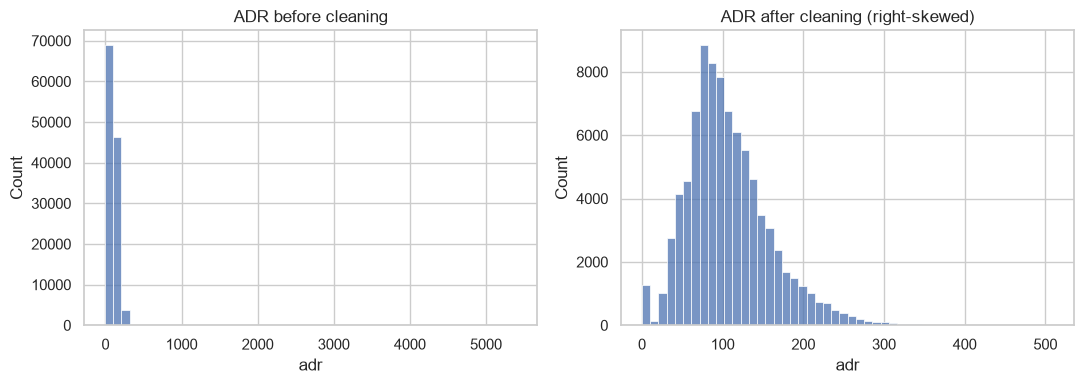

In [32]:
# What changed between raw and clean?
comparison = pd.DataFrame({
    "raw": raw.groupby("deposit_type")["is_canceled"].mean(),
    "clean": df.groupby("deposit_type")["is_canceled"].mean(),
}).round(3)
comparison.loc["ALL BOOKINGS"] = [raw["is_canceled"].mean().round(3), df["is_canceled"].mean().round(3)]
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(raw["adr"], bins=50, ax=axes[0])
axes[0].set_title("ADR before cleaning")
sns.histplot(df["adr"], bins=50, ax=axes[1])
axes[1].set_title("ADR after cleaning (right-skewed)")
plt.tight_layout()
plt.show()

### **Step 4: Feature engineering**



| Feature | How it's built | Why (business reasoning) |
|---|---|---|
| **`total_nights`** | weekend nights + week nights | Length of stay is a single, meaningful booking size. Two separate night columns describe it indirectly. It should help price (longer stays may get discounted rates) and cancellation (longer stays are bigger commitments). |
| **`total_guests`** | adults + children + babies | Party size drives room type and price, and it is the base for the family and group patterns. A single count is easier for models than three separate columns. |
| **`is_family`** | 1 if children or babies are present | Families plan differently from solo or business travellers: they book around school holidays, want larger rooms, and may cancel differently. The flag captures this in one signal, where `children` and `babies` alone split it across two sparse columns. |
| **`weekend_ratio`** | weekend nights / total nights | Separates leisure trips (weekend-heavy) from business trips (weekday-heavy). `total_nights` alone can't do this, since a 2-night Saturday stay and a 2-night Tuesday stay look the same. It's a possible price driver, since weekend rates often differ. |
| **`season`** | month mapped to winter, spring, summer or autumn | Months with similar demand behave alike, so grouping them reduces 12 categories to 4 and makes the seasonal pattern clearer. |


In [33]:
df["total_nights"] = df["stays_in_week_nights"] + df["stays_in_weekend_nights"]
df["total_guests"] =df["adults"] + df["babies"] + df["children"]
df["is_family"] = ( (df["children"] > 0 ) | (df["babies"] > 0)).astype(int)
df["weekend_ratio"] = (df["stays_in_weekend_nights"] / df["total_nights"])


df["season"] = df["arrival_date_month"].map(SEASON_MAP)

In [34]:
# check if any missing values are created in the new columns 
print(df[["total_nights","total_guests","weekend_ratio","season"]].isna().sum())
print(df["season"].value_counts())
print(df["weekend_ratio"].between(0, 1).all())   # should be True


total_nights     0
total_guests     0
weekend_ratio    0
season           0
dtype: int64
season
summer    28841
spring    23520
autumn    18342
winter    15668
Name: count, dtype: int64
True


## 6. Train/test split and preprocessing pipeline

**One split for every module**, so all models are judged on the same test rows.

- `test_size=0.2`: 80% to learn from, 20% held back for the final score.
- `stratify=is_canceled`: keeps the cancellation rate the same in both sets.
- `random_state=42`: makes the split repeatable.

In [35]:
train_df, test_df = train_test_split(
    df, test_size=TEST_SIZE, stratify=df["is_canceled"], random_state=RANDOM_STATE
)
print(f"train: {len(train_df):,} rows, cancel rate {train_df['is_canceled'].mean():.4f}")
print(f"test : {len(test_df):,} rows, cancel rate {test_df['is_canceled'].mean():.4f}")

# Features exclude BOTH targets: adr is the target for Module A, is_canceled for Module B
X_train = train_df.drop(columns=TARGETS)
X_test = test_df.drop(columns=TARGETS)

y_cancel_train, y_cancel_test = train_df["is_canceled"], test_df["is_canceled"]
y_adr_train, y_adr_test = train_df["adr"], test_df["adr"]

assert not set(TARGETS) & set(X_train.columns)

train: 69,096 rows, cancel rate 0.2747
test : 17,275 rows, cancel rate 0.2747


### Column groups

`exclude="number"` selects every non-numeric column, which avoids the pandas warning that `include="object"` raises on newer versions.

In [36]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

# Every feature must be in exactly one list
assert set(num_cols) | set(cat_cols) == set(X_train.columns)
assert not set(num_cols) & set(cat_cols)

print(f"{len(num_cols)} numeric columns:\n{num_cols}\n")
print(f"{len(cat_cols)} categorical columns:\n{cat_cols}")

20 numeric columns:
['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'required_car_parking_spaces', 'total_of_special_requests', 'total_nights', 'total_guests', 'is_family', 'weekend_ratio']

12 categorical columns:
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'agent', 'customer_type', 'season']


### The pipeline

| Part | What it does and why |
|---|---|
| `SimpleImputer` | Fills any missing value (median for numbers, most common for categories). The data has none now, but the Streamlit app may receive incomplete input. |
| `StandardScaler` | Converts each number to (value - mean) / std. Needed by KNN, SVM, K-Means and PCA so that `lead_time` (0 to 700) does not drown out `adults` (0 to 4). |
| `OneHotEncoder` | Turns each category into 0/1 columns. `min_frequency=100` groups categories with fewer than 100 training rows into one "infrequent" bucket (rare countries and agents), and `handle_unknown` sends unseen categories there instead of crashing. |
| `ColumnTransformer` | Applies the numeric pipeline to numeric columns and the categorical one to categorical columns. |

`fit_transform` on train learns the statistics; `transform` on test only applies them.

In [37]:
def build_preprocessor(num_cols, cat_cols):
    """Shared preprocessing for all modules. Will move to src/features.py."""
    num_pipe = Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
    ])
    cat_pipe = Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist",
                             min_frequency=100, sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", num_pipe, num_cols),
        ("cat", cat_pipe, cat_cols),
    ])


preprocess = build_preprocessor(num_cols, cat_cols)

X_train_p = preprocess.fit_transform(X_train)   # learn from train, then transform
X_test_p = preprocess.transform(X_test)         # reuse the train statistics

print("train:", X_train_p.shape, " test:", X_test_p.shape)

train: (69096, 171)  test: (17275, 171)


In [38]:
# Proof that the scaler used TRAIN statistics: train is exactly 0 / 1, test is close but not exact
n = len(num_cols)
scaling_check = pd.DataFrame({
    "train mean": X_train_p[:, :n].mean(axis=0),
    "train std": X_train_p[:, :n].std(axis=0),
    "test mean": X_test_p[:, :n].mean(axis=0),
    "test std": X_test_p[:, :n].std(axis=0),
}, index=num_cols).round(2)
scaling_check

,train mean,train std,test mean,test std
lead_time,0.0,1.0,-0.01,1.00
arrival_date_year,0.0,1.0,-0.00,1.00
arrival_date_week_number,0.0,1.0,0.00,1.00
arrival_date_day_of_month,0.0,1.0,0.00,1.00
stays_in_weekend_nights,-0.0,1.0,0.00,1.01
stays_in_week_nights,0.0,1.0,0.00,1.00
adults,-0.0,1.0,0.00,0.95
children,-0.0,1.0,-0.01,0.98
babies,-0.0,1.0,0.01,1.38
is_repeated_guest,0.0,1.0,-0.01,0.97


## 7. Save and summary

In [39]:

df.to_csv(DATA_CLEAN, index=False)
print(f"Saved {len(df):,} rows x {df.shape[1]} columns to {DATA_CLEAN}")

Saved 86,371 rows x 34 columns to ../data/clean/hotel_clean.csv


### What Day 1 produced

- Cleaned dataset with engineered features, saved once to `data/clean/hotel_clean.csv`.
- A shared stratified train/test split and a preprocessing pipeline fitted on train only.
- Five written insights and a logged record of every cleaning decision.
